In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler,LabelEncoder
from sklearn.impute import SimpleImputer

In [ ]:
df = pd.read_csv('/content/test.csv')
data = df
print('DataSet loaded succesfully')

DataSet loaded succesfully


In [ ]:
print(data.head())

   Unnamed: 0     id  Gender      Customer Type   Age   Type of Travel  \
0           0  19556  Female     Loyal Customer  52.0  Business travel   
1           1  90035  Female     Loyal Customer  36.0  Business travel   
2           2  12360    Male  disloyal Customer  20.0  Business travel   
3           3  77959    Male     Loyal Customer  44.0  Business travel   
4           4  36875  Female     Loyal Customer  49.0  Business travel   

      Class  Flight Distance  Inflight wifi service  \
0       Eco              160                      5   
1  Business             2863                      1   
2       Eco              192                      2   
3  Business             3377                      0   
4       Eco             1182                      2   

   Departure/Arrival time convenient  ...  Inflight entertainment  \
0                                  4  ...                       5   
1                                  1  ...                       4   
2                

In [ ]:
df.shape

(25976, 25)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25976 entries, 0 to 25975
Data columns (total 25 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Unnamed: 0                         25976 non-null  int64  
 1   id                                 25976 non-null  int64  
 2   Gender                             25976 non-null  object 
 3   Customer Type                      25976 non-null  object 
 4   Age                                25957 non-null  float64
 5   Type of Travel                     25976 non-null  object 
 6   Class                              25940 non-null  object 
 7   Flight Distance                    25976 non-null  int64  
 8   Inflight wifi service              25976 non-null  int64  
 9   Departure/Arrival time convenient  25976 non-null  int64  
 10  Ease of Online booking             25976 non-null  int64  
 11  Gate location                      25976 non-null  int

In [ ]:
df.describe()

,Unnamed: 0,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,25976.000000,25976.000000,25957.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.000000,25976.00000,25893.000000
mean,12987.500000,65005.657992,39.621489,1193.788459,2.724746,3.046812,2.756775,2.977094,3.215353,3.261665,3.449222,3.357753,3.385664,3.350169,3.633238,3.314175,3.649253,3.286226,14.30609,14.740857
std,7498.769632,37611.526647,15.136962,998.683999,1.335384,1.533371,1.412951,1.282133,1.331506,1.355536,1.320090,1.338299,1.282088,1.318862,1.176525,1.269332,1.180681,1.319330,37.42316,37.517539
min,0.000000,17.000000,7.000000,31.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.00000,0.000000
25%,6493.750000,32170.500000,27.000000,414.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,2.000000,0.00000,0.000000
50%,12987.500000,65319.500000,40.000000,849.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,3.000000,0.00000,0.000000
75%,19481.250000,97584.250000,51.000000,1744.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,5.000000,4.000000,12.00000,13.000000
max,25975.000000,129877.000000,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1128.00000,1115.000000


In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
id,0
Gender,0
Customer Type,0
Age,19
Type of Travel,0
Class,36
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0


In [ ]:
print("No of duplicaterows:",df.duplicated().sum())

No of duplicaterows: 0


In [ ]:
df['Age'] = df['Age'].fillna(df['Age'].mean())
df['Class'] = df['Class'].fillna(df['Class'].mode()[0])

In [ ]:
df.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,19556,Female,Loyal Customer,52.0,Business travel,Eco,160,5,4,...,5,5,5,5,2,5,5,50,44.0,satisfied
1,1,90035,Female,Loyal Customer,36.0,Business travel,Business,2863,1,1,...,4,4,4,4,3,4,5,0,0.0,satisfied
2,2,12360,Male,disloyal Customer,20.0,Business travel,Eco,192,2,0,...,2,4,1,3,2,2,2,0,0.0,neutral or dissatisfied
3,3,77959,Male,Loyal Customer,44.0,Business travel,Business,3377,0,0,...,1,1,1,1,3,1,4,0,6.0,satisfied
4,4,36875,Female,Loyal Customer,49.0,Business travel,Eco,1182,2,3,...,2,2,2,2,4,2,4,0,20.0,satisfied


In [ ]:
df.drop('Arrival Delay in Minutes', axis=1, inplace=True)

In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
id,0
Gender,0
Customer Type,0
Age,0
Type of Travel,0
Class,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0


In [ ]:
le = LabelEncoder()
df['Gender'] = le.fit_transform(df['Gender'])
print(df['Gender'].head())

0    0
1    0
2    1
3    1
4    0
Name: Gender, dtype: int64


In [ ]:
scaler = MinMaxScaler()
df[['Age','Flight Distance']] = scaler.fit_transform(df[['Age','Flight Distance']])
print(df[['Age','Flight Distance']].head())

        Age  Flight Distance
0  0.576923         0.026050
1  0.371795         0.571890
2  0.166667         0.032512
3  0.474359         0.675687
4  0.538462         0.232431


In [ ]:
df['InflightComfortScore'] = df['Seat comfort'] + df['Leg room service'] + df['Food and drink'] + df['Cleanliness']
print('InflightComfortScore feature Created')
display(df[["Seat comfort", "Leg room service", "Food and drink", "Cleanliness", "InflightComfortScore"]].head())

InflightComfortScore feature Created


,Seat comfort,Leg room service,Food and drink,Cleanliness,InflightComfortScore
0,3,5,3,5,16
1,5,4,5,5,19
2,2,1,2,2,7
3,4,1,3,4,12
4,2,2,4,4,12


In [ ]:
df['IsDelayed'] = df['Departure Delay in Minutes'].apply(lambda x: 1 if x > 0 else 0)
print('IsDelayed feature Created')
display(df[["Departure Delay in Minutes", "IsDelayed"]].head())

IsDelayed feature Created


,Departure Delay in Minutes,IsDelayed
0,50,1
1,0,0
2,0,0
3,0,0
4,0,0


In [ ]:
Q1 = df['Age'].quantile(0.25)
Q3 = df['Age'].quantile(0.75)
IQR = Q3-Q1
lower_bound = Q1-1.5*IQR
upper_bound = Q3+1.5*IQR
outliers = df[(df['Age']>=lower_bound) | (df['Age']<=upper_bound)]
print("Outliers Removed")

Outliers Removed


In [ ]:
df.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,satisfaction,InflightComfortScore,IsDelayed
0,0,19556,0,Loyal Customer,0.576923,Business travel,Eco,0.026050,5,4,...,5,5,5,2,5,5,50,satisfied,16,1
1,1,90035,0,Loyal Customer,0.371795,Business travel,Business,0.571890,1,1,...,4,4,4,3,4,5,0,satisfied,19,0
2,2,12360,1,disloyal Customer,0.166667,Business travel,Eco,0.032512,2,0,...,4,1,3,2,2,2,0,neutral or dissatisfied,7,0
3,3,77959,1,Loyal Customer,0.474359,Business travel,Business,0.675687,0,0,...,1,1,1,3,1,4,0,satisfied,12,0
4,4,36875,0,Loyal Customer,0.538462,Business travel,Eco,0.232431,2,3,...,2,2,2,4,2,4,0,satisfied,12,0


In [ ]:
print("Data Set shape After Removing Outliers:",df.shape)

Data Set shape After Removing Outliers: (25976, 26)


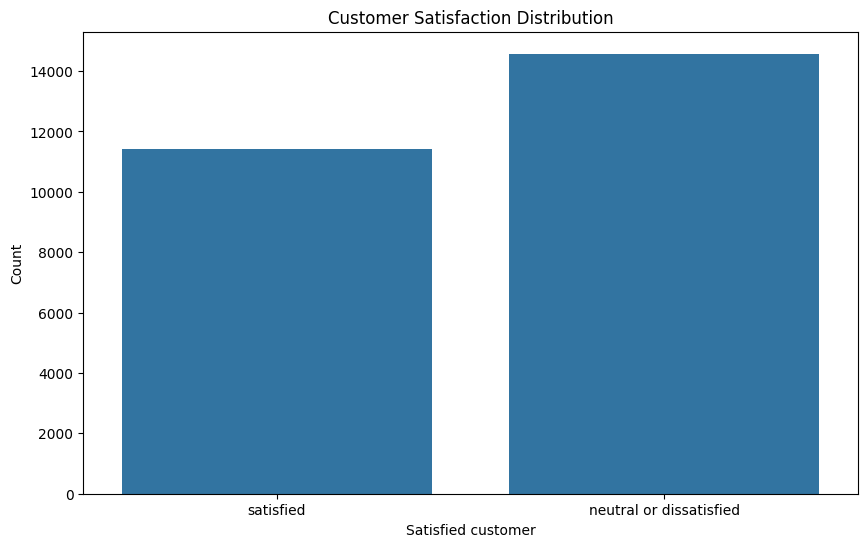

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(x='satisfaction',data=df)
plt.title('Customer Satisfaction Distribution')
plt.xlabel('Satisfied customer')
plt.ylabel('Count')
plt.show()

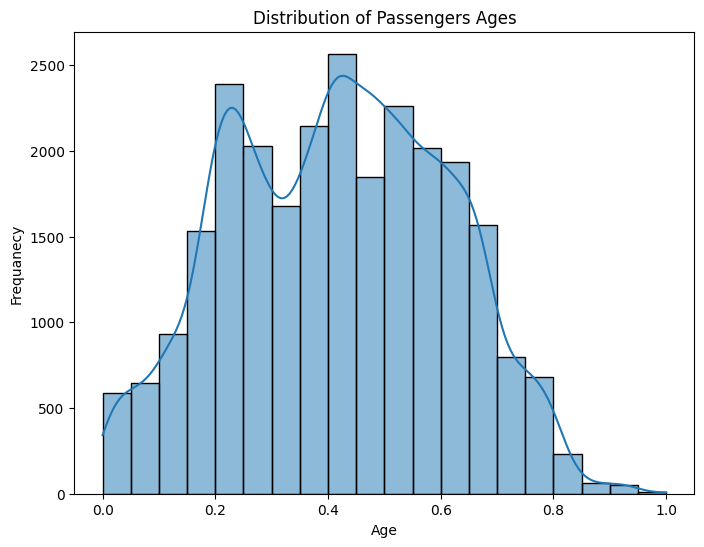

In [ ]:
plt.figure(figsize=(8,6))
sns.histplot(df['Age'],bins=20,kde=True)
plt.title('Distribution of Passengers Ages')
plt.xlabel('Age')
plt.ylabel('Frequanecy')
plt.show()

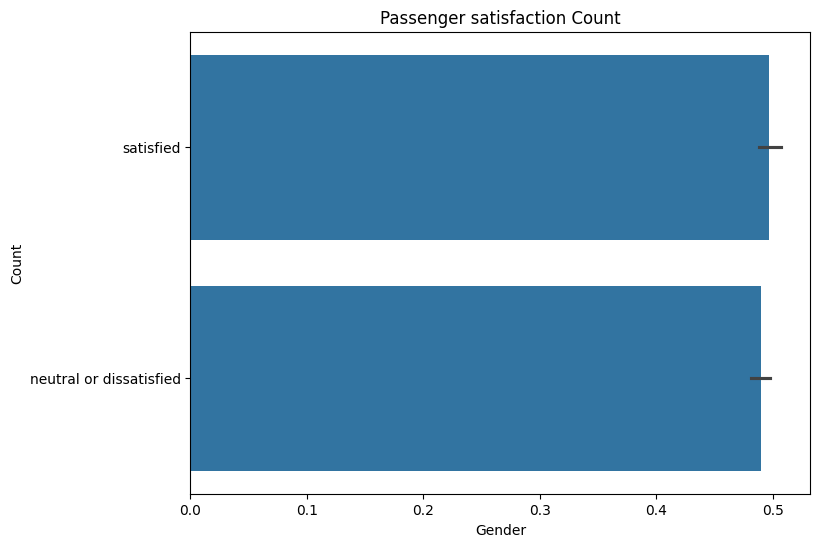

In [ ]:
plt.figure(figsize=(8,6))
sns.barplot(x='Gender',y='satisfaction',data=df)
plt.title('Passenger satisfaction Count')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

In [ ]:
drop_columns = ['Customer Type','Type of Travel']
df.drop(drop_columns, axis=1, inplace=True)
df.head()

,Unnamed: 0,id,Gender,Age,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,19556,Female,52.0,Eco,160,5,4,3,4,...,5,5,5,5,2,5,5,50,44.0,satisfied
1,1,90035,Female,36.0,Business,2863,1,1,3,1,...,4,4,4,4,3,4,5,0,0.0,satisfied
2,2,12360,Male,20.0,Eco,192,2,0,2,4,...,2,4,1,3,2,2,2,0,0.0,neutral or dissatisfied
3,3,77959,Male,44.0,Business,3377,0,0,0,2,...,1,1,1,1,3,1,4,0,6.0,satisfied
4,4,36875,Female,49.0,Eco,1182,2,3,4,3,...,2,2,2,2,4,2,4,0,20.0,satisfied


In [ ]:
print("Before preprocessing")
print(data.head(10))
print("After preprocessing")
print(df.head(10))

Before preprocessing
   Unnamed: 0     id  Gender   Age     Class  Flight Distance  \
0           0  19556  Female  52.0       Eco              160   
1           1  90035  Female  36.0  Business             2863   
2           2  12360    Male  20.0       Eco              192   
3           3  77959    Male  44.0  Business             3377   
4           4  36875  Female  49.0       Eco             1182   
5           5  39177    Male  16.0       Eco              311   
6           6  79433  Female  77.0  Business             3987   
7           7  97286  Female  43.0  Business             2556   
8           8  27508    Male  47.0       Eco              556   
9           9  62482  Female  46.0  Business             1744   

   Inflight wifi service  Departure/Arrival time convenient  \
0                      5                                  4   
1                      1                                  1   
2                      2                                  0   
3          